<a href="https://colab.research.google.com/github/KineticBlaze23/Metodos-Numericos/blob/main/Deber_Metodo_de_la_biseccion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## ESCUELA POLITÉCNICA NACIONAL

---

## MÉTODOS NUMÉRICOS

### Deber: Método de Bisección en Python

---

**Estudiante:** Fabio Pillajo  
**Curso:** GR1 CC  
**Fecha:** 26 de octubre de 2026

---
  

In [44]:
# Librerias utilizadas
import math
import numpy as np
import matplotlib.pyplot as plt

#Implementacion metodo de la biseccion
def biseccion(f, a, b, TOL=1e-6, N0=100):
    """Devuelve (p, historia), con historia = [(a, b, p) por iteración]."""
    FA = f(a)
    historia = []
    i = 1
    while i <= N0:
        p = a + (b-a)/2                                     # COMPLETE: punto medio estable
        FP = f(p)
        historia.append((a,b,p))                        # COMPLETE: (a, b, p)
        if FP == 0 or (b-a)/2 < TOL:                          # COMPLETE: parada por TOL
            return p, historia
        i = i + 1
        if FA * FP > 0:
            a = p
            FA = FP                                   # COMPLETE: mover a y FA
        else:
            b = p                                     # COMPLETE: mover b
    raise RuntimeError(f"fracasó después de {N0} iteraciones")



### RESOLUCION DE EJERCICIOS

In [30]:
# 1: x^3 - x - 1 = 0 en [1, 2] con TOL = 1e-4

f1 = lambda x: x**3 - x - 1

raiz1, _ = biseccion(f1, 1.0, 2.0, 1e-4, 100)
print(f"1: {raiz1:.6f}")



# 2: x^3 - 7x^2 + 14x - 6 = 0 con TOL = 1e-2

f2 = lambda x: x**3 - 7*x**2 + 14*x - 6

raiz2_1, _ = biseccion(f2, 0.0, 1.0, 1e-2, 100)
print(f"2.1: {raiz2_1:.6f}")

raiz2_2, _ = biseccion(f2, 1.0, 3.2, 1e-2, 100)
print(f"2.2: {raiz2_2:.6f}")

raiz2_3, _ = biseccion(f2, 3.2, 4.0, 1e-2, 100)
print(f"2.3: {raiz2_3:.6f}")



# 3: Funciones Trigonometricas y exponencial


# 3.1. x = 2*sin(x) con TOL = 1e-5
f3_1 = lambda x: x - 2 * math.sin(x)
raiz3_1, _ = biseccion(f3_1, 1.0, 2.0, 1e-5, 100)
print(f"3.1: {raiz3_1:.6f}")

# 3.2. x = tan(x) con TOL = 1e-5
f3_2 = lambda x: x - math.tan(x)
raiz3_2, _ = biseccion(f3_2, 4.0, 4.6, 1e-5, 100)
print(f"3.2: {raiz3_2:.6f}")

# 3.3. x^2 - 1 = e^(1 - x^2) en [-2, 0] con TOL = 1e-3
f3_3 = lambda x: (x**2 - 1) - math.exp(1 - x**2)
raiz3_3, _ = biseccion(f3_3, -2.0, 0.0, 1e-3, 100)
print(f"3.3: {raiz3_3:.6f}")





1: 1.324768
2.1: 0.585938
2.2: 3.002344
2.3: 3.418750
3.1: 1.895500
3.2: 4.493405
3.3: -1.250977


### PROBLEMAS APLICADOS

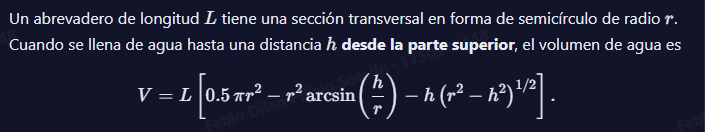

In [40]:
#Definir la funcion
L = 10.0
r = 1.0
V = 12.4
tol = 0.01

f4 = lambda h: L * (0.5 * math.pi * r**2 - (r**2) * math.asin(h / r) - h * (r**2 - h**2)**0.5) - V

h, _ = biseccion(f, 0.0, r, tol, 100)

print(f"h: {h:.6f}")
print(f"Profundidad: {r - h:.6f}")


h: 0.164062
Profundidad: 0.835938


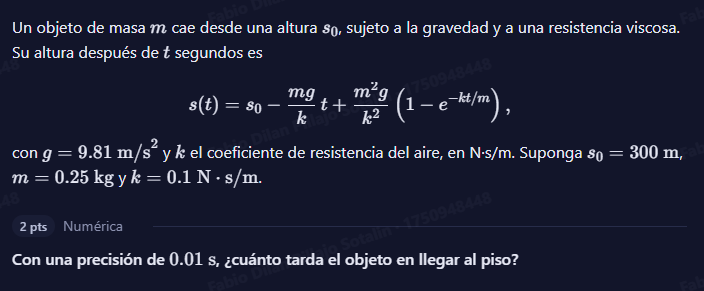

In [46]:
# Definición de la función s(t)
g = 9.81
s0, m, k = 300.0, 0.25, 0.1
tol = 0.01

def s(t):
    return s0 - (m * g / k) * t + (m ** 2 * g / k ** 2) * (1 - np.exp(-k * t / m))

# Método de bisección
tiempo, iters = biseccion(s, 0.0, 20.0, tol, 100)

print(f"Tiempo: {tiempo:.6f}")



Tiempo: 14.716797


### GRAFICA

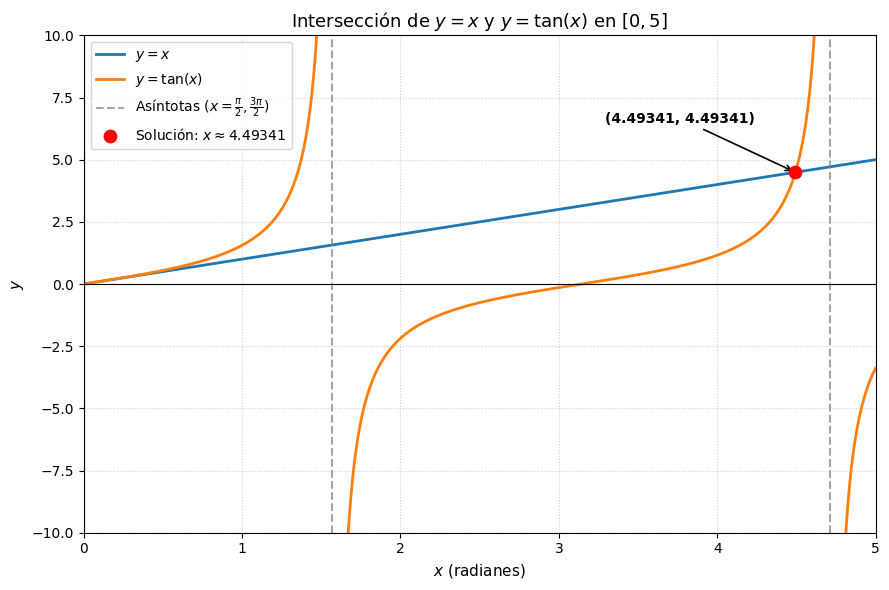

In [50]:
x = np.linspace(0, 5, 2000)

# 2. Funciones
y_recta = x
y_tan = np.tan(x)

# Evitar trazos verticales continuos en las asíntotas de tan(x)
y_tan[:-1][np.diff(y_tan) < -10] = np.nan

# 3. Raíz encontrada por bisección
raiz = 4.49341

# 4. Graficación
plt.figure(figsize=(9, 6))

plt.plot(x, y_recta, label=r'$y = x$', color='tab:blue', linewidth=2)
plt.plot(x, y_tan, label=r'$y = \tan(x)$', color='tab:orange', linewidth=2)

# Asíntotas verticales de tan(x) en [0, 5]: pi/2 y 3pi/2
plt.axvline(np.pi / 2, color='gray', linestyle='--', alpha=0.7, label=r'Asíntotas ($x = \frac{\pi}{2}, \frac{3\pi}{2}$)')
plt.axvline(3 * np.pi / 2, color='gray', linestyle='--', alpha=0.7)

# Marcar el punto de intersección (solución positiva)
plt.scatter([raiz], [raiz], color='red', s=80, zorder=5, label=f'Solución: $x \\approx {raiz:.5f}$')
plt.annotate(f'({raiz:.5f}, {raiz:.5f})',
             xy=(raiz, raiz),
             xytext=(raiz - 1.2, raiz + 2),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
             fontsize=10,
             fontweight='bold')

# Configuración de los ejes
plt.xlim(0, 5)
plt.ylim(-10, 10)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.grid(True, linestyle=':', alpha=0.6)

plt.title(r'Intersección de $y = x$ y $y = \tan(x)$ en $[0, 5]$', fontsize=13)
plt.xlabel('$x$ (radianes)', fontsize=11)
plt.ylabel('$y$', fontsize=11)
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()